# E0. Thiết lập đánh giá

Trước khi so sánh bất kỳ mô hình hay cách tiền xử lý nào, cần thống nhất **đo bằng gì** và **đo thế nào**
(Bài 05: Đánh giá mô hình). Notebook này trả lời ba câu hỏi:

1. **Độ đo**: vì sao dùng ROC AUC thay vì accuracy / F1?
2. **Quy trình đánh giá**: vì sao dùng K-fold CV (5 fold cố định trong `data/folds.csv`) thay vì đánh giá trên tập
   train hay một lần tách train/test?
3. **Rò rỉ dữ liệu (leakage)**: thế nào là dự đoán out-of-fold (OOF) "sạch", và OOF "bẩn" làm điểm CV sai lệch
   bao nhiêu?

Mô hình dùng ở đây chỉ là công cụ minh hoạ (Logistic Regression, Decision Tree, LightGBM với cấu hình đơn giản);
so sánh mô hình nằm ở E3.

> **Trong cuộc thi.** `data/folds.csv` được tạo ngày 12/10 (`src/make_folds.py`) và dùng cho mọi model, mọi stack.
> Quy tắc OOF sạch áp dụng từ model đầu tiên (14/10, `A_lgb_v1`): early stopping trên 10% tách từ phần train của
> fold, target encoding tính trong fold. Khi chuyển sang stacking, ngưỡng giữ một thay đổi được siết dần: +3e-5 ổn
> định qua 3 meta seed (18/10), rồi tăng ở cả 3 seed, ≥ 10/15 fold và ≥ +5e-6 (20/10). Notebook này dựng lại các
> quy tắc đó và đo bằng số vì sao chúng cần thiết.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import time

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import rankdata
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, log_loss, roc_auc_score, roc_curve
from sklearn.model_selection import KFold, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

from config import CAT_COLS, FEATURES, NUM_COLS, RESULTS_DIR, SCORE_COLS, TARGET
from cv import log_result, run_cv
from data import load_data
import plot as P

pd.set_option("display.width", 200)
train, test = load_data()
y = train[TARGET].values
DEP, ARR = "Departure Delay in Minutes", "Arrival Delay in Minutes"
N_JOBS = 6  # giới hạn số luồng để máy không quá tải

## 1. Độ đo
### 1.1 Mô hình baseline
Logistic Regression với tiền xử lý tối thiểu: điền `Arrival Delay` bằng `Departure Delay`, log1p hai cột delay,
chuẩn hoá z-score cột số và cột điểm, one-hot cột category. Toàn bộ pipeline nằm trong `fit_predict` nên chỉ học
từ phần train của mỗi fold.

In [2]:
def basic_frame(X):
    X = X.copy()
    X[ARR] = X[ARR].fillna(X[DEP])
    X[DEP], X[ARR] = np.log1p(X[DEP]), np.log1p(X[ARR])
    return X


def lr_pipeline(C=1.0):
    pre = ColumnTransformer([
        ("num", StandardScaler(), NUM_COLS + SCORE_COLS),
        ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_COLS),
    ])
    return make_pipeline(FunctionTransformer(basic_frame), pre, LogisticRegression(C=C, max_iter=500))


def fp_lr(X_tr, y_tr, X_va, X_te):
    m = lr_pipeline().fit(X_tr, y_tr)
    return m.predict_proba(X_va)[:, 1], m.predict_proba(X_te)[:, 1]


base = run_cv(fp_lr, train, test, FEATURES, name="E0_lr_baseline")
log_result("E0_setup", "lr_baseline", base, notes="LR + one-hot + z-score + log1p delay; baseline cho E2/E3")
oof = base["oof"]

  fold 0: AUC 0.922563 (2s)


  fold 1: AUC 0.921549 (4s)


  fold 2: AUC 0.921539 (6s)


  fold 3: AUC 0.921460 (8s)


  fold 4: AUC 0.921509 (10s)


CV AUC 0.921725 | fold mean 0.921724 ± 0.000421
Đã lưu oof_E0_lr_baseline.npy, test_E0_lr_baseline.npy | CV AUC = 0.921725


### 1.2 AUC chỉ phụ thuộc thứ tự
Biến đổi xác suất dự đoán bằng một hàm đồng biến (luỹ thừa, thứ hạng, kéo giãn logit): AUC giữ nguyên, còn
accuracy và F1 ở ngưỡng 0,5 và log loss đều thay đổi. Bài toán chấm bằng AUC nên chỉ cần **xếp hạng** hành khách
đúng, không cần chỉnh ngưỡng hay hiệu chỉnh xác suất.

In [3]:
logit = np.log(oof / (1 - oof))
variants = {
    "p (gốc)": oof,
    "p³": oof ** 3,
    "rank(p) / n": rankdata(oof) / len(oof),
    "sigmoid(2·logit p)": 1 / (1 + np.exp(-2 * logit)),
}
inv = pd.DataFrame({
    name: {"AUC": roc_auc_score(y, p), "accuracy @0,5": accuracy_score(y, p > 0.5),
           "F1 @0,5": f1_score(y, p > 0.5), "log loss": log_loss(y, np.clip(p, 1e-7, 1 - 1e-7))}
    for name, p in variants.items()
}).T
inv.to_csv(RESULTS_DIR / "E0_metric_invariance.csv")
inv.round(5)

,AUC,"accuracy @0,5","F1 @0,5",log loss
p (gốc),0.92172,0.87841,0.86082,0.34390
p³,0.92172,0.84604,0.80066,0.61320
rank(p) / n,0.92172,0.85293,0.84414,0.41666
sigmoid(2·logit p),0.92172,0.87841,0.86082,0.43385


### 1.3 Accuracy / F1 phụ thuộc ngưỡng, AUC thì không
Nhãn khá cân bằng (44% hài lòng) nên accuracy không quá sai lệch, nhưng vẫn phải chọn ngưỡng. ROC và AUC tổng hợp
mọi ngưỡng cùng lúc.

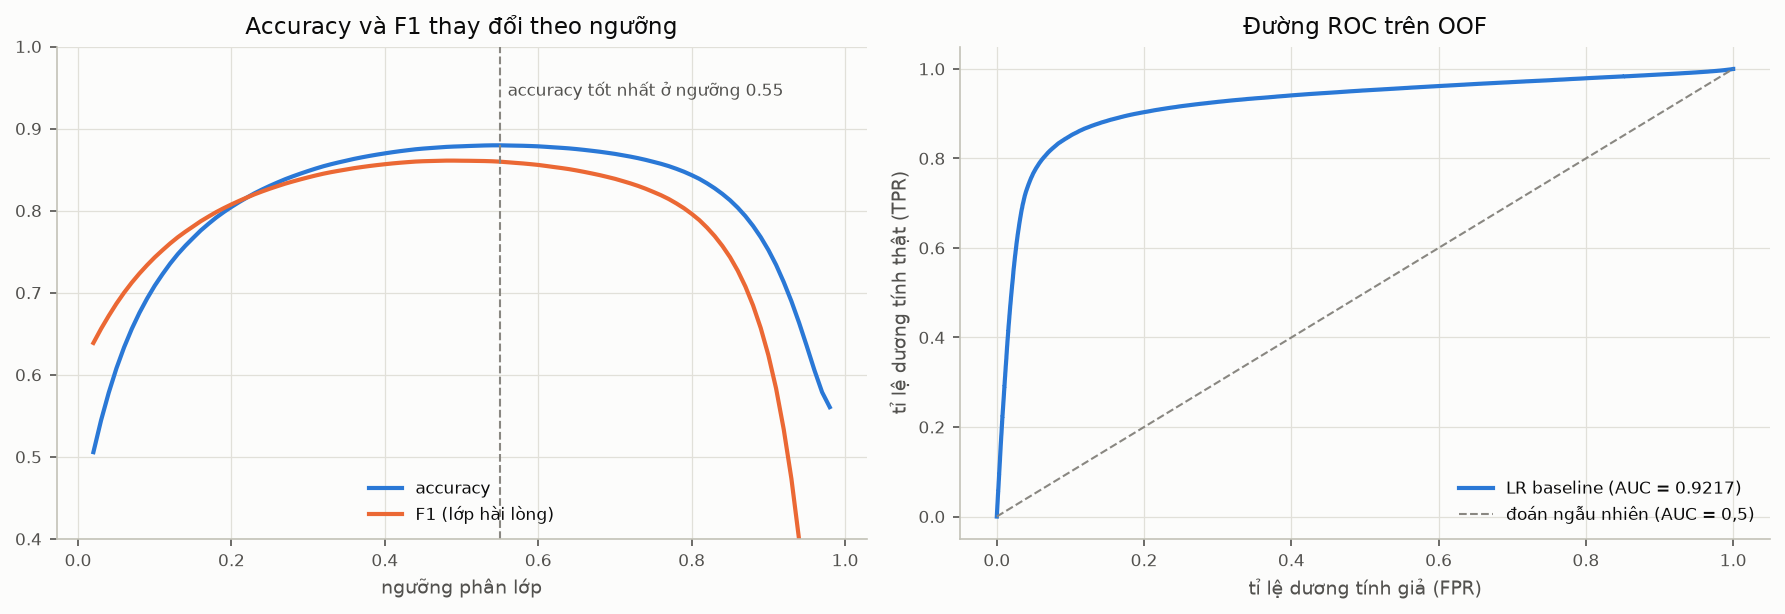

In [4]:
th = np.linspace(0.02, 0.98, 97)
acc = [accuracy_score(y, oof > t) for t in th]
f1 = [f1_score(y, oof > t) for t in th]
fpr, tpr, _ = roc_curve(y, oof)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].plot(th, acc, color=P.BLUE, label="accuracy")
axes[0].plot(th, f1, color=P.ORANGE, label="F1 (lớp hài lòng)")
best = th[int(np.argmax(acc))]
axes[0].axvline(best, color=P.REF, ls="--", lw=1)
axes[0].text(best + 0.01, 0.94, f"accuracy tốt nhất ở ngưỡng {best:.2f}", fontsize=8, color=P.INK_2)
axes[0].set_xlabel("ngưỡng phân lớp")
axes[0].set_ylim(0.4, 1)
axes[0].set_title("Accuracy và F1 thay đổi theo ngưỡng")
axes[0].legend(loc="lower center")
axes[1].plot(fpr, tpr, color=P.BLUE, label=f"LR baseline (AUC = {base['cv_auc']:.4f})")
axes[1].plot([0, 1], [0, 1], color=P.REF, ls="--", lw=1, label="đoán ngẫu nhiên (AUC = 0,5)")
axes[1].set_xlabel("tỉ lệ dương tính giả (FPR)")
axes[1].set_ylabel("tỉ lệ dương tính thật (TPR)")
axes[1].set_title("Đường ROC trên OOF")
axes[1].legend(loc="lower right")
fig.tight_layout()
P.save(fig, "E0_01_threshold_roc")

**Nhận xét mục 1**
- LR baseline đạt CV AUC 0,92172; 5 fold nằm trong 0,9215–0,9226 (độ lệch chuẩn 0,0004). Đây là mốc so sánh cho
  E2 và E3.
- Bốn cách biến đổi đồng biến cho **AUC giống hệt** (0,92172), trong khi accuracy ở ngưỡng 0,5 giảm từ 0,878 xuống
  0,846, F1 từ 0,861 xuống 0,801, log loss tăng từ 0,344 lên 0,613. AUC chỉ đo khả năng xếp hạng.
- Accuracy cao nhất khoảng 0,88 ở ngưỡng 0,55; F1 lại tốt nhất ở ngưỡng khác. Dùng accuracy hay F1 thì phải chọn
  ngưỡng, thêm một chỗ có thể overfit. Đường ROC tổng hợp mọi ngưỡng cùng lúc.
- **Quyết định:** đánh giá bằng AUC trên OOF, đúng độ đo của cuộc thi; nộp xác suất, không chỉnh ngưỡng; khi kết hợp
  nhiều mô hình có thể trộn trên thứ hạng hoặc logit mà không làm hỏng độ đo (E5).

## 2. Ba quy trình đánh giá (Bài 05)
### 2.1 Quy trình 1: đánh giá ngay trên tập train
So AUC trên chính dữ liệu đã học với AUC 5-fold CV. Cây quyết định không giới hạn độ sâu nhớ thuộc lòng dữ liệu
nên AUC trên train gần 1, nhưng CV thấp hơn hẳn (overfitting). LR đơn giản gần như không chênh.

In [5]:
def tree_frame(X):
    X = basic_frame(X)
    for c in CAT_COLS:
        X[c] = X[c].astype("category").cat.codes
    return X


def fp_tree(depth):
    def fp(X_tr, y_tr, X_va, X_te):
        m = DecisionTreeClassifier(max_depth=depth, random_state=42).fit(tree_frame(X_tr), y_tr)
        return m.predict_proba(tree_frame(X_va))[:, 1], m.predict_proba(tree_frame(X_te))[:, 1]
    return fp


rows = []
for name, fp in [("Logistic Regression", fp_lr), ("Decision Tree (depth 10)", fp_tree(10)),
                 ("Decision Tree (không giới hạn)", fp_tree(None))]:
    p_tr, _ = fp(train[FEATURES], y, train[FEATURES], test[FEATURES].head(5))
    res = base if name == "Logistic Regression" else run_cv(fp, train, test, FEATURES, verbose=False)
    rows.append({"mô hình": name, "AUC trên train (QT1)": roc_auc_score(y, p_tr), "AUC 5-fold CV (QT3)": res["cv_auc"]})
qt1 = pd.DataFrame(rows).set_index("mô hình")
qt1["chênh lệch"] = qt1.iloc[:, 0] - qt1.iloc[:, 1]
qt1.to_csv(RESULTS_DIR / "E0_resubstitution.csv")
qt1.round(4)

,AUC trên train (QT1),AUC 5-fold CV (QT3),chênh lệch
mô hình,,,
Logistic Regression,0.9217,0.9217,0.0000
Decision Tree (depth 10),0.9543,0.9513,0.0031
Decision Tree (không giới hạn),1.0000,0.8641,0.1359


### 2.2 Quy trình 2 (một lần tách train/test) và quy trình 3 (K-fold)
Lặp 10 lần tách ngẫu nhiên 80/20 với 10 seed khác nhau (QT2), so với 5 fold cố định (QT3). Mỗi lần tách cho một
con số khác nhau; trung bình 5 fold ổn định hơn và mọi dòng train đều được dự đoán đúng một lần (OOF), dùng được
cho ensemble ở E5.

*Các lần tách ngẫu nhiên ở đây chỉ để minh hoạ độ dao động của quy trình; mọi so sánh mô hình trong đồ án đều dùng
`folds.csv`.*

In [6]:
hold = []
for seed in range(10):
    tr_i, va_i = train_test_split(np.arange(len(train)), test_size=0.2, stratify=y, random_state=seed)
    m = lr_pipeline().fit(train.loc[tr_i, FEATURES], y[tr_i])
    hold.append(roc_auc_score(y[va_i], m.predict_proba(train.loc[va_i, FEATURES])[:, 1]))
hold = np.array(hold)
fold_auc = np.array(base["fold_auc"])
proc = pd.DataFrame({
    "QT2: holdout 80/20 (10 seed)": {"trung bình": hold.mean(), "độ lệch chuẩn": hold.std(), "min": hold.min(), "max": hold.max()},
    "QT3: từng fold (5 fold)": {"trung bình": fold_auc.mean(), "độ lệch chuẩn": fold_auc.std(), "min": fold_auc.min(), "max": fold_auc.max()},
}).T
proc["max - min"] = proc["max"] - proc["min"]
proc.to_csv(RESULTS_DIR / "E0_holdout_vs_kfold.csv")
print(f"Ước lượng độ lệch chuẩn của trung bình 5 fold ≈ {fold_auc.std(ddof=1) / np.sqrt(5):.6f}")
proc.round(6)

Ước lượng độ lệch chuẩn của trung bình 5 fold ≈ 0.000210


,trung bình,độ lệch chuẩn,min,max,max - min
QT2: holdout 80/20 (10 seed),0.921473,0.000681,0.920264,0.922495,0.002232
QT3: từng fold (5 fold),0.921724,0.000421,0.921460,0.922563,0.001104


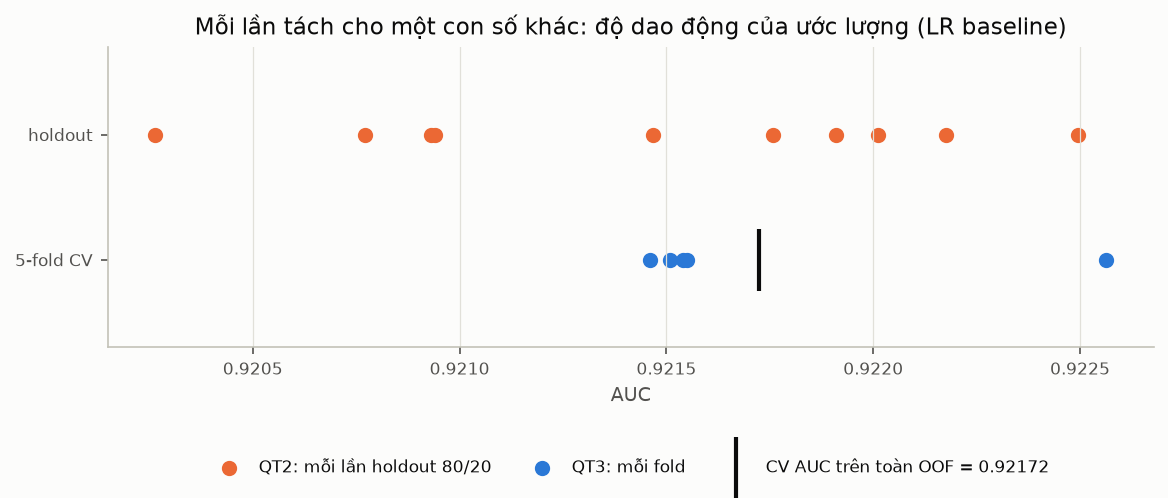

In [7]:
fig, ax = plt.subplots(figsize=(9, 2.6))
ax.scatter(hold, np.full_like(hold, 1), color=P.ORANGE, s=40, label="QT2: mỗi lần holdout 80/20")
ax.scatter(fold_auc, np.full_like(fold_auc, 0), color=P.BLUE, s=40, label="QT3: mỗi fold")
ax.scatter([base["cv_auc"]], [0], marker="|", s=900, color=P.INK, label=f"CV AUC trên toàn OOF = {base['cv_auc']:.5f}")
ax.set_yticks([0, 1], ["5-fold CV", "holdout"])
ax.set_ylim(-0.7, 1.7)
ax.set_xlabel("AUC")
ax.set_title("Mỗi lần tách cho một con số khác: độ dao động của ước lượng (LR baseline)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.32), ncol=3)
ax.grid(axis="y", visible=False)
P.save(fig, "E0_02_holdout_vs_kfold")

**Nhận xét mục 2**
- **Quy trình 1 sai lệch nặng với mô hình phức tạp.** LR cho AUC trên train bằng CV (0,9217): mô hình đơn giản,
  bias cao, không overfit. Cây độ sâu 10 chênh 0,003. Cây không giới hạn đạt 1,0000 trên train nhưng chỉ 0,8641 trên
  CV, chênh 0,136: nó thuộc lòng dữ liệu (overfitting, Bài 07).
- **Một lần holdout dao động nhiều.** 10 lần tách 80/20 cho AUC từ 0,9203 đến 0,9225 (biên độ 0,0022, độ lệch chuẩn
  0,0007). Trung bình 5 fold có độ lệch chuẩn ước lượng khoảng 0,0002, nhỏ hơn khoảng 3 lần. Hai mô hình chênh nhau
  0,0005 có thể đảo thứ tự chỉ vì cách chia nếu đánh giá bằng một lần holdout.
- So sánh hai mô hình trên **cùng** 5 fold (theo cặp) còn ổn định hơn so sánh hai con số trung bình, vì độ khó
  riêng của từng fold bị triệt tiêu. Vì vậy mọi bảng kết quả đều kèm chênh lệch từng fold và số fold tăng.
- K-fold còn cho dự đoán OOF trên toàn bộ 700 nghìn dòng train, nguyên liệu cho stacking ở E5.

## 3. OOF sạch và OOF bẩn: rò rỉ dữ liệu làm CV "đẹp giả"
Để thấy CV bị sai lệch bao nhiêu, cần một tập **chưa từng đụng tới**. Ta dùng fold 0–3 làm tập phát triển (dev,
chạy CV 4 fold như bình thường) và giữ **fold 4 làm test giả**. Mô hình sạch thì CV trên dev xấp xỉ điểm trên
fold 4; mô hình bẩn thì CV cao hơn hẳn điểm thật.

Mô hình: LightGBM (category để dạng `category`). Xét hai kiểu rò rỉ hay gặp:
- **(a) Target encoding tính ngoài fold.** Mã hoá "hồ sơ 13 điểm dịch vụ" (rất nhiều giá trị khác nhau) bằng tỉ lệ
  hài lòng trung bình của hồ sơ đó. Bản bẩn tính tỉ lệ trên toàn bộ dev một lần, gồm cả nhãn của fold đang chấm
  và nhãn của chính dòng đó. Bản sạch tính trong từng fold, dòng train dùng giá trị out-of-fold lồng trong.
- **(b) Early stopping trên fold đang chấm.** Bản bẩn dừng sớm theo chính fold validation (chọn số cây tốt nhất cho
  fold đó). Bản sạch tách 10% từ phần train của fold để dừng sớm.

In [8]:
dev_mask = train["fold"].values != 4
dev = train[dev_mask].reset_index(drop=True)
hold4 = train[~dev_mask].reset_index(drop=True)
y_dev, y_hold = dev[TARGET].values, hold4[TARGET].values
profile = lambda df: pd.util.hash_pandas_object(df[SCORE_COLS], index=False).values  # noqa: E731
print(f"dev {len(dev)} dòng (fold 0-3), test giả {len(hold4)} dòng (fold 4)")
print(f"Số hồ sơ 13 điểm khác nhau trong dev: {len(np.unique(profile(dev))):,}")


def te_map(keys, target, m=20):
    """Tỉ lệ hài lòng theo khoá, làm trơn về tỉ lệ chung với trọng số m."""
    g = pd.DataFrame({"k": keys, "y": target}).groupby("k")["y"].agg(["sum", "count"])
    prior = target.mean()
    return ((g["sum"] + m * prior) / (g["count"] + m)), prior


def te_apply(keys, mapping, prior):
    return pd.Series(keys).map(mapping).fillna(prior).values


def te_oof(keys, target, n_splits=5):
    """TE cho chính các dòng train: mỗi dòng lấy giá trị tính từ các dòng khác fold (lồng trong)."""
    out = np.zeros(len(keys))
    for a, b in KFold(n_splits, shuffle=True, random_state=42).split(keys):
        mp, pr = te_map(keys[a], target[a])
        out[b] = te_apply(keys[b], mp, pr)
    return out


def lgb_frame(df, te=None):
    X = df[FEATURES].copy()
    for c in CAT_COLS:
        X[c] = X[c].astype("category")
    if te is not None:
        X["te_profile"] = te
    return X


LGB = dict(learning_rate=0.1, num_leaves=63, min_child_samples=50, subsample=0.8, subsample_freq=1,
           colsample_bytree=0.8, n_jobs=N_JOBS, verbose=-1, random_state=42)


def dev_cv_and_holdout(make_sets, n_estimators=300):
    """CV 4 fold trên dev + điểm trên fold 4 (trung bình dự đoán của 4 model fold, như khi nộp bài)."""
    fold_dev = dev["fold"].values
    oof_dev = np.zeros(len(dev))
    p_hold = np.zeros(len(hold4))
    for k in range(4):
        tr, va = fold_dev != k, fold_dev == k
        X_tr, X_va, X_ho = make_sets(tr, va)
        m = lgb.LGBMClassifier(n_estimators=n_estimators, **LGB).fit(X_tr, y_dev[tr])
        oof_dev[va] = m.predict_proba(X_va)[:, 1]
        p_hold += m.predict_proba(X_ho)[:, 1] / 4
    return roc_auc_score(y_dev, oof_dev), roc_auc_score(y_hold, p_hold)


keys_dev, keys_hold = profile(dev), profile(hold4)
mp_all, pr_all = te_map(keys_dev, y_dev)
te_leak_dev = te_apply(keys_dev, mp_all, pr_all)  # bẩn: dùng cả nhãn fold đang chấm + nhãn chính dòng đó


def sets_none(tr, va):
    return lgb_frame(dev[tr]), lgb_frame(dev[va]), lgb_frame(hold4)


def sets_leak(tr, va):
    return (lgb_frame(dev[tr], te_leak_dev[tr]), lgb_frame(dev[va], te_leak_dev[va]),
            lgb_frame(hold4, te_apply(keys_hold, mp_all, pr_all)))


def sets_clean(tr, va):
    mp, pr = te_map(keys_dev[tr], y_dev[tr])
    return (lgb_frame(dev[tr], te_oof(keys_dev[tr], y_dev[tr])), lgb_frame(dev[va], te_apply(keys_dev[va], mp, pr)),
            lgb_frame(hold4, te_apply(keys_hold, mp, pr)))


leak_rows = []
for name, fn in [("không TE (21 cột gốc)", sets_none), ("TE bẩn (tính trên toàn dev)", sets_leak),
                 ("TE sạch (tính trong fold)", sets_clean)]:
    t0 = time.time()
    cv_auc, hold_auc = dev_cv_and_holdout(fn)
    leak_rows.append({"kiểu": "(a) target encoding", "biến thể": name, "CV trên dev": cv_auc, "AUC fold 4 (thật)": hold_auc})
    print(f"{name}: CV {cv_auc:.5f} | fold 4 {hold_auc:.5f} ({time.time() - t0:.0f}s)")

dev 559708 dòng (fold 0-3), test giả 139927 dòng (fold 4)
Số hồ sơ 13 điểm khác nhau trong dev: 285,650


không TE (21 cột gốc): CV 0.95810 | fold 4 0.95899 (20s)


TE bẩn (tính trên toàn dev): CV 0.99345 | fold 4 0.90817 (21s)


TE sạch (tính trong fold): CV 0.95778 | fold 4 0.95881 (21s)


In [9]:
def es_cv_and_holdout(clean):
    fold_dev = dev["fold"].values
    oof_dev, p_hold, iters = np.zeros(len(dev)), np.zeros(len(hold4)), []
    for k in range(4):
        tr_idx, va_idx = np.where(fold_dev != k)[0], np.where(fold_dev == k)[0]
        if clean:
            fit_idx, es_idx = train_test_split(tr_idx, test_size=0.1, stratify=y_dev[tr_idx], random_state=42)
        else:
            fit_idx, es_idx = tr_idx, va_idx
        m = lgb.LGBMClassifier(n_estimators=3000, **LGB).fit(
            lgb_frame(dev.iloc[fit_idx]), y_dev[fit_idx],
            eval_set=[(lgb_frame(dev.iloc[es_idx]), y_dev[es_idx])], eval_metric="auc",
            callbacks=[lgb.early_stopping(100, verbose=False)])
        iters.append(m.best_iteration_)
        oof_dev[va_idx] = m.predict_proba(lgb_frame(dev.iloc[va_idx]))[:, 1]
        p_hold += m.predict_proba(lgb_frame(hold4))[:, 1] / 4
    return roc_auc_score(y_dev, oof_dev), roc_auc_score(y_hold, p_hold), iters


for name, clean in [("ES bẩn (dừng theo fold đang chấm)", False), ("ES sạch (tách 10% từ phần train)", True)]:
    t0 = time.time()
    cv_auc, hold_auc, iters = es_cv_and_holdout(clean)
    leak_rows.append({"kiểu": "(b) early stopping", "biến thể": name, "CV trên dev": cv_auc, "AUC fold 4 (thật)": hold_auc})
    print(f"{name}: CV {cv_auc:.5f} | fold 4 {hold_auc:.5f} | số cây {iters} ({time.time() - t0:.0f}s)")

leak = pd.DataFrame(leak_rows)
leak["CV − thật"] = leak["CV trên dev"] - leak["AUC fold 4 (thật)"]
leak.to_csv(RESULTS_DIR / "E0_leakage.csv", index=False)
leak.round(5)

ES bẩn (dừng theo fold đang chấm): CV 0.95831 | fold 4 0.95903 | số cây [109, 112, 148, 198] (22s)


ES sạch (tách 10% từ phần train): CV 0.95812 | fold 4 0.95905 | số cây [157, 173, 117, 154] (17s)


,kiểu,biến thể,CV trên dev,AUC fold 4 (thật),CV − thật
0,(a) target encoding,không TE (21 cột gốc),0.95810,0.95899,-0.00088
1,(a) target encoding,TE bẩn (tính trên toàn dev),0.99345,0.90817,0.08528
2,(a) target encoding,TE sạch (tính trong fold),0.95778,0.95881,-0.00102
3,(b) early stopping,ES bẩn (dừng theo fold đang chấm),0.95831,0.95903,-0.00072
4,(b) early stopping,ES sạch (tách 10% từ phần train),0.95812,0.95905,-0.00093


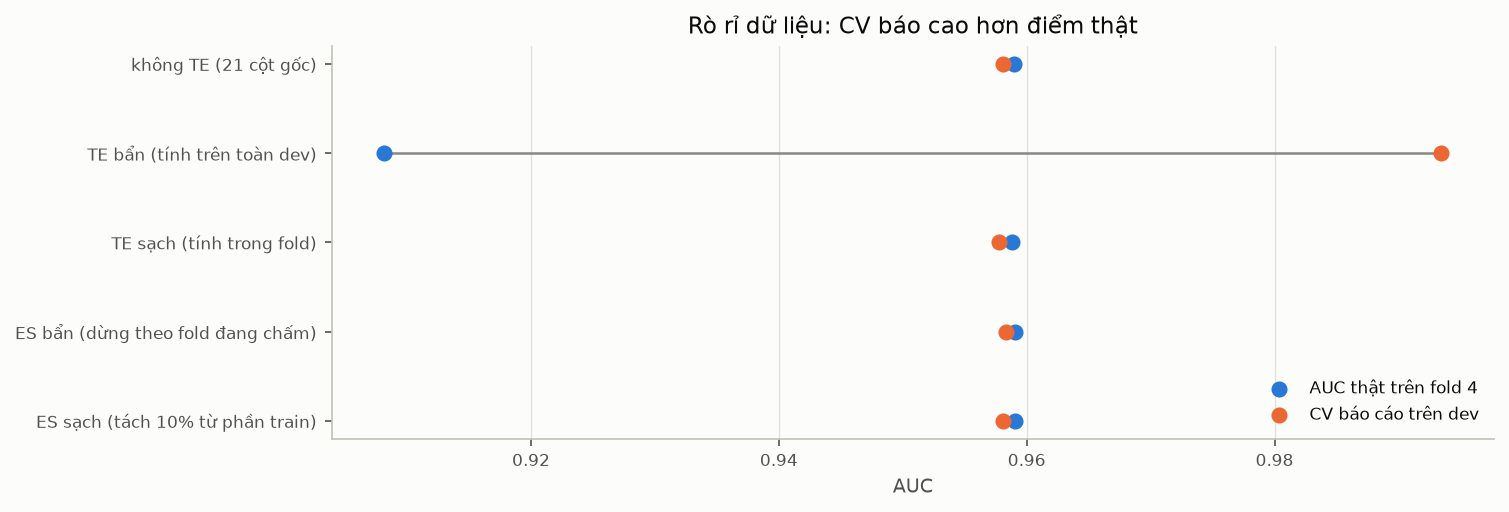

In [10]:
fig, ax = plt.subplots(figsize=(10, 3.4))
yy = np.arange(len(leak))[::-1]
ax.scatter(leak["AUC fold 4 (thật)"], yy, color=P.BLUE, s=45, zorder=3, label="AUC thật trên fold 4")
ax.scatter(leak["CV trên dev"], yy, color=P.ORANGE, s=45, zorder=3, label="CV báo cáo trên dev")
for yi, a, b in zip(yy, leak["AUC fold 4 (thật)"], leak["CV trên dev"]):
    ax.plot([a, b], [yi, yi], color=P.INK_3, lw=1.2, zorder=2)
ax.set_yticks(yy, leak["biến thể"])
ax.set_xlabel("AUC")
ax.set_title("Rò rỉ dữ liệu: CV báo cao hơn điểm thật")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
P.save(fig, "E0_03_leakage")

**Nhận xét mục 3**
- **TE bẩn: CV 0,9935 nhưng điểm thật 0,9082**, CV báo cao hơn 0,085, và điểm thật còn thấp hơn hẳn mô hình không
  dùng TE (0,9590). Dev có 285.650 hồ sơ điểm khác nhau trên 560 nghìn dòng; phần lớn hồ sơ chỉ có 1–2 dòng, nên
  TE tính cả nhãn của chính dòng đó gần như **chép lại nhãn**. Mô hình học cách đọc nhãn thay vì học quy luật.
- **TE sạch**: CV 0,9578, thật 0,9588, khớp với không dùng TE. Feature này thật ra không giúp gì: tính sạch thì
  thấy ngay, tính bẩn thì tưởng là đột phá.
- **Early stopping bẩn** làm CV tăng 0,0002 (0,95831 so với 0,95812) nhưng điểm thật trên fold 4 không đổi
  (0,95903 so với 0,95905). Sai lệch nhỏ, nhưng cùng cỡ với chênh lệch giữa các phương án ở giai đoạn stacking
  (vài phần triệu đến vài phần vạn), đủ để chọn sai phương án.
- Ở mọi biến thể sạch, AUC trên fold 4 cao hơn CV khoảng 0,001: fold 4 hơi "dễ" hơn trung bình. Vì vậy cần so các
  biến thể với nhau, không so CV với một con số đơn lẻ.

## 4. Quy ước đánh giá cho toàn bộ đồ án
1. Một bộ fold duy nhất `data/folds.csv` (StratifiedKFold 5 fold, seed 42) cho mọi thí nghiệm và mọi mô hình.
2. Độ đo: AUC trên dự đoán OOF. Mỗi kết quả báo cáo CV AUC trên toàn bộ OOF, trung bình ± độ lệch chuẩn 5 fold,
   chênh lệch so với baseline và số fold tăng (`src/cv.py`).
3. Mọi bước học từ dữ liệu (điền thiếu, chuẩn hoá, target encoding, chọn feature, gom cụm, PCA) chỉ fit trên phần
   train của fold; `run_cv` bắt buộc điều này qua hàm `fit_predict`.
4. Early stopping dùng 10% tách từ phần train của fold, hoặc cố định số vòng lặp.
5. Chỉ giữ một thay đổi khi nó tăng ở phần lớn fold (và qua nhiều seed với thay đổi nhỏ). Chênh lệch nhỏ hơn độ dao
   động giữa các lần chia thì coi như bằng nhau.
6. Public leaderboard (60 nghìn dòng) chỉ để tham khảo; đối chiếu CV, public và private ở E6.